In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
np.random.seed(42)
tf.random.set_seed(42)

LOOK_BACK = 30

In [3]:
df = pd.read_csv("../data/AMZN_Stock_Updated_V2.csv", index_col=0, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True).dropna().reset_index(drop=True)

In [4]:
prev_close = df["Close"].shift(1)
feat = pd.DataFrame({
    "ret_open":  np.log(df["Open"] / prev_close),
    "ret_high":  np.log(df["High"] / prev_close),
    "ret_low":   np.log(df["Low"] / prev_close),
    "ret_close": np.log(df["Close"] / prev_close),
    "log_vol":   np.log1p(df["Volume"]),
})

In [5]:
df = df.iloc[1:].reset_index(drop=True)
feat = feat.iloc[1:].reset_index(drop=True)
prev_close = prev_close.iloc[1:].reset_index(drop=True)

In [6]:
X_raw = feat.values
y_raw = feat["ret_close"].values
close_arr = df["Close"].values
dates_arr = df["Date"].values
n = len(feat)

In [7]:
train_end = int(n * 0.70)
val_end = int(n * 0.85)

In [8]:
feat_scaler = StandardScaler().fit(X_raw[:train_end])
tgt_scaler = StandardScaler().fit(y_raw[:train_end].reshape(-1, 1))
X_s = feat_scaler.transform(X_raw)
y_s = tgt_scaler.transform(y_raw.reshape(-1, 1)).flatten()

In [9]:
def make_windows(start, end):
    Xs, ys, ts = [], [], []
    for t in range(max(start, LOOK_BACK), end):
        Xs.append(X_s[t - LOOK_BACK:t])
        ys.append(y_s[t])
        ts.append(t)
    return np.array(Xs), np.array(ys), np.array(ts)

In [10]:
X_tr, y_tr, t_tr = make_windows(0, train_end)
X_va, y_va, t_va = make_windows(train_end, val_end)
X_te, y_te, t_te = make_windows(val_end, n)


In [11]:
model = Sequential([
    SimpleRNN(32, input_shape=(LOOK_BACK, X_raw.shape[1])),
    Dropout(0.2),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.summary()

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 32)                  │           1,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,249 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history = model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=100,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 1.2127 - val_loss: 0.3247
Epoch 2/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.0899 - val_loss: 0.3146
Epoch 3/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.0454 - val_loss: 0.3124
Epoch 4/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.0400 - val_loss: 0.3092
Epoch 5/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.0076 - val_loss: 0.3064
Epoch 6/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1.0126 - val_loss: 0.3063
Epoch 7/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.9915 - val_loss: 0.3053
Epoch 8/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.9965 - val_loss: 0.3051
Epoch 9/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.9802 - val_loss: 0.3022
Epoch 10/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.9838 - val_loss: 0.3024
Epoch 11/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.9682 - val_loss: 0.3043
Epoch 12/100
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step

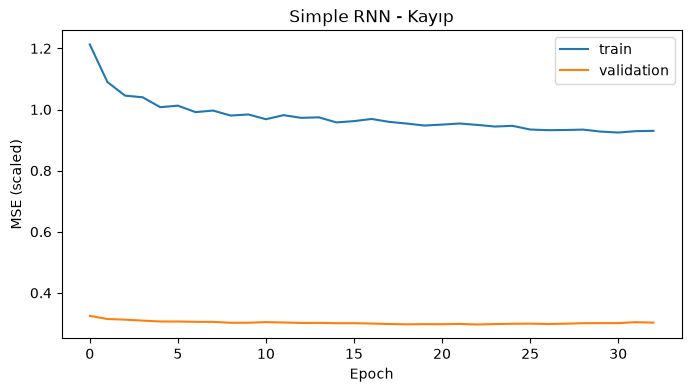

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)"); plt.legend()
plt.title("Simple RNN - Kayıp")
plt.show()

In [14]:
pred_ret = tgt_scaler.inverse_transform(
    model.predict(X_te, verbose=0).reshape(-1, 1)
).flatten()
true_ret = tgt_scaler.inverse_transform(y_te.reshape(-1, 1)).flatten()


In [15]:
prev_close_te = close_arr[t_te - 1]
true_price = close_arr[t_te]
pred_price = prev_close_te * np.exp(pred_ret)
test_dates = dates_arr[t_te]

In [16]:
def report(name, y_true, y_hat):
    rmse = np.sqrt(mean_squared_error(y_true, y_hat))
    mae = mean_absolute_error(y_true, y_hat)
    print(f"{name:<18} RMSE={rmse:8.3f}   MAE={mae:8.3f}")

In [17]:
print("\n--- Fiyat tahmini (test) ---")
report("Naive (dünkü)", true_price, prev_close_te)
report("Simple RNN", true_price, pred_price)



--- Fiyat tahmini (test) ---
Naive (dünkü)      RMSE=   3.137   MAE=   2.293
Simple RNN         RMSE=   3.170   MAE=   2.317


In [18]:
dir_acc = (np.sign(pred_ret) == np.sign(true_ret)).mean()
print(f"\nYön doğruluğu (Simple RNN): {dir_acc:.3f}")
print(f"Hep 'yükseliş' baseline   : {(true_ret > 0).mean():.3f}")


Yön doğruluğu (Simple RNN): 0.498
Hep 'yükseliş' baseline   : 0.511


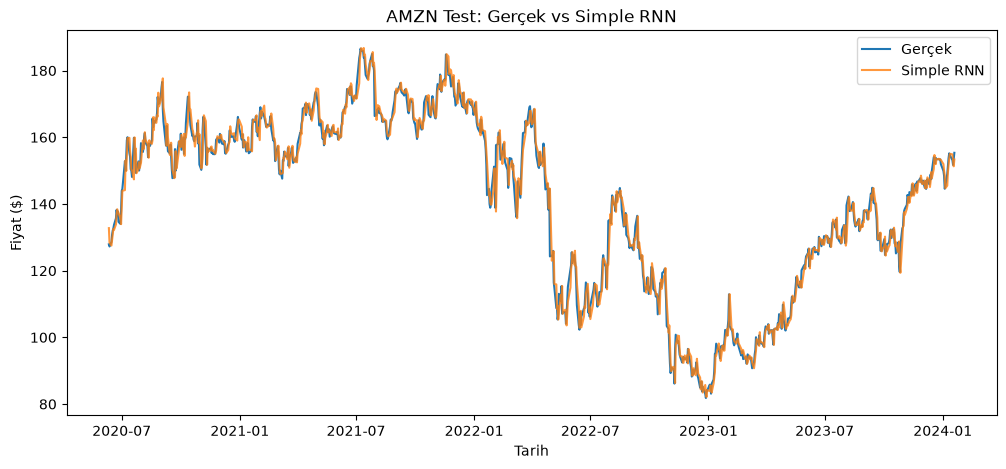

In [19]:
# 10) Grafik
plt.figure(figsize=(12, 5))
plt.plot(test_dates, true_price, label="Gerçek")
plt.plot(test_dates, pred_price, label="Simple RNN", alpha=0.8)
plt.legend(); plt.title("AMZN Test: Gerçek vs Simple RNN")
plt.xlabel("Tarih"); plt.ylabel("Fiyat ($)")
plt.show()

In [21]:
model.save("../model/amazonn_stock_price_rnn.keras")